In [1]:

import os.path as op
import hnn_core
from hnn_core import simulate_dipole, read_params, jones_2009_model

hnn_core_root = op.dirname(hnn_core.__file__)

params_fname = op.join(hnn_core_root, 'param', 'gamma_L5weak_L2weak.json')
params = read_params(params_fname)
print(params['gbar_L*'])

{
    "gbar_L2Basket_L2Basket": 0.01,
    "gbar_L2Basket_L2Pyr_gabaa": 0.007,
    "gbar_L2Basket_L2Pyr_gabab": 0.0,
    "gbar_L2Basket_L5Pyr": 0.0,
    "gbar_L2Pyr_L2Basket": 0.0012,
    "gbar_L2Pyr_L2Pyr_ampa": 0.0,
    "gbar_L2Pyr_L2Pyr_nmda": 0.0,
    "gbar_L2Pyr_L5Basket": 0.0,
    "gbar_L2Pyr_L5Pyr": 0.0,
    "gbar_L5Basket_L5Basket": 0.0075,
    "gbar_L5Basket_L5Pyr_gabaa": 0.08,
    "gbar_L5Basket_L5Pyr_gabab": 0.0,
    "gbar_L5Pyr_L5Basket": 0.00091,
    "gbar_L5Pyr_L5Pyr_ampa": 0.0,
    "gbar_L5Pyr_L5Pyr_nmda": 0.0
}


In [2]:
net = jones_2009_model(params)

weights_ampa = {'L2_pyramidal': 0.0008, 'L5_pyramidal': 0.0075}
synaptic_delays = {'L2_pyramidal': 0.1, 'L5_pyramidal': 1.0}
rate_constant = {'L2_pyramidal': 140.0, 'L5_pyramidal': 40.0}
net.add_poisson_drive(
    'poisson', rate_constant=rate_constant, weights_ampa=weights_ampa,
    location='proximal', synaptic_delays=synaptic_delays,
    event_seed=1349)

In [3]:
dpls = simulate_dipole(net, tstop=250.)
scaling_factor = 30000
dpls = [dpl.scale(scaling_factor) for dpl in dpls]  # scale in place

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Trial 1: 200.0 ms...
Trial 1: 210.0 ms...
Trial 1: 220.0 ms...
Trial 1: 230.0 ms...
Trial 1: 240.0 ms...
Applying Jones baseline correction


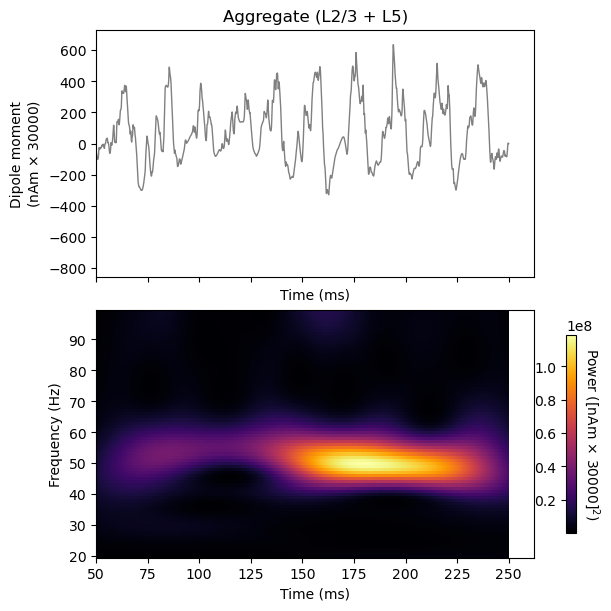

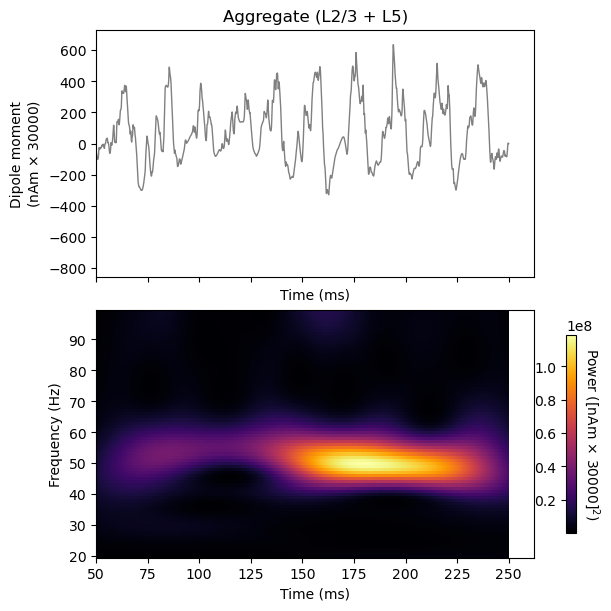

In [4]:
tmin = 50
trial_idx = 0  # pick first trial

# plot dipole time course and time-frequency representation in same figure
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6),
                         constrained_layout=True)

dpls[trial_idx].plot(tmin=tmin, ax=axes[0], show=False)

# Create an fixed-step tiling of frequencies from 20 to 100 Hz in steps of 1 Hz
freqs = np.arange(20., 100., 1.)
dpls[trial_idx].plot_tfr_morlet(freqs, n_cycles=7, tmin=tmin, ax=axes[1])

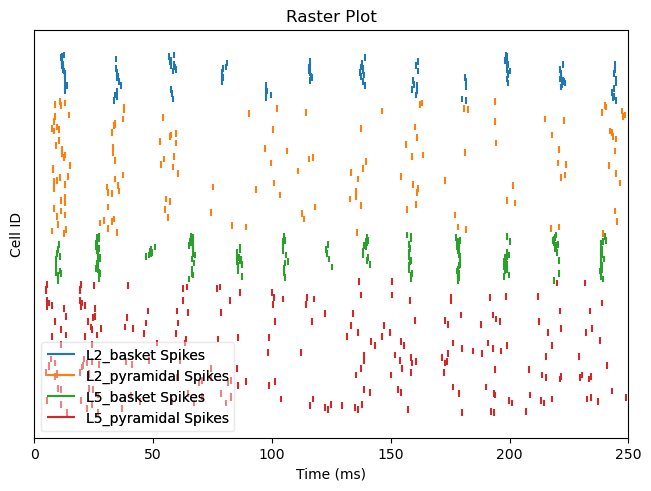

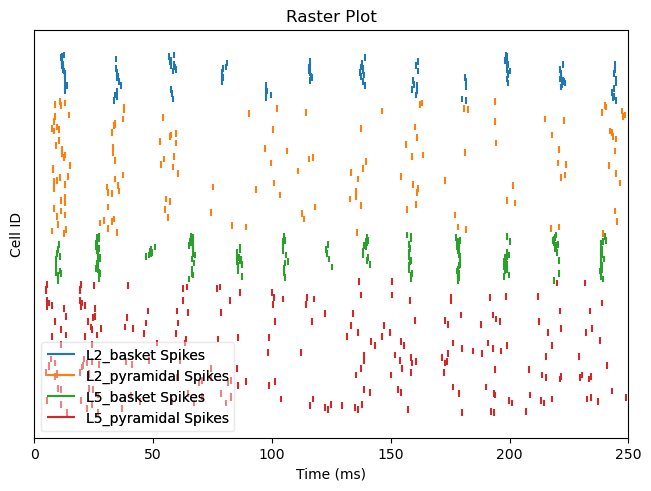

In [5]:
net.cell_response.plot_spikes_raster()